# Your Very First Machine Learning (ML) Model: Logistic Regression

Dataset: [College Student Placement Factors Dataset](https://www.kaggle.com/datasets/sahilislam007/college-student-placement-factors-dataset) (`data/college_student_placement_dataset.csv`)

In [1]:
# Import our libraries.

from IPython.display import display

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, precision_score, recall_score, confusion_matrix, f1_score

import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

import statsmodels.api as sm

## Constants

It is a good programming practice to use constants to avoid repetition errors and to save yourself the effort of retyping the expression by _centralizing_ semantically identical values.

`DATASET_PATH` identifies the path to the dataset being loaded and operated on. `RANDOM_STATE` makes otherwise random operations reproducible run after run. Keep whatever value you set it to unless you want slightly different results.

In [2]:
DATASET_PATH = "data/college_student_placement_dataset.csv"
RANDOM_STATE = 45  # DO NOT CHANGE THIS RANDOM STATE.

## Preliminary Inspection

See what the raw file looks like!

In [3]:
# Look at the first 5 lines of theraw contents of the file first.

with open(DATASET_PATH, "r") as file:
    for line_number in range(5):
        if line := file.readline():
            print(line)
        else:
            break  # Stop; there are less than 5 lines.

College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement

CLG0030,107,6.61,6.28,8,No,8,8,4,No

CLG0061,97,5.52,5.37,8,No,7,8,0,No

CLG0036,109,5.36,5.83,9,No,3,1,1,No

CLG0055,122,5.47,5.75,6,Yes,1,6,1,No



## Preliminary Load

Load the data. This is not the final form of the data which will be used, but it’s a `DataFrame` for further inspection so we can decide what to do with it next.

In [4]:
# Load the dataset into a pandas dataframe.

df = pd.read_csv(DATASET_PATH)
df

,College_ID,IQ,Prev_Sem_Result,CGPA,Academic_Performance,Internship_Experience,Extra_Curricular_Score,Communication_Skills,Projects_Completed,Placement
0,CLG0030,107,6.61,6.28,8,No,8,8,4,No
1,CLG0061,97,5.52,5.37,8,No,7,8,0,No
2,CLG0036,109,5.36,5.83,9,No,3,1,1,No
3,CLG0055,122,5.47,5.75,6,Yes,1,6,1,No
4,CLG0004,96,7.91,7.69,7,No,8,10,2,No
...,...,...,...,...,...,...,...,...,...,...
9995,CLG0021,119,8.41,8.29,4,No,1,8,0,Yes
9996,CLG0098,70,9.25,9.34,7,No,0,7,2,No
9997,CLG0066,89,6.08,6.25,3,Yes,3,9,5,No
9998,CLG0045,107,8.77,8.92,3,No,7,5,1,No


## Null Values Check
Inspect which varibles may be good / not good for using as features based on null values. 


In [5]:
# Identify which columns have null values.
df.isnull().sum()

College_ID                0
IQ                        0
Prev_Sem_Result           0
CGPA                      0
Academic_Performance      0
Internship_Experience     0
Extra_Curricular_Score    0
Communication_Skills      0
Projects_Completed        0
Placement                 0
dtype: int64

## Duplicate Rows Check
If so, remove the duplicates.

In [6]:
# Check to see if our data has any duplicate rows.
print("Duplacates: ", df.duplicated().sum())

Duplacates:  0


Many clean… 😐

## Categorical Categories

What are the categories for the categorial-looking (i.e., non-numeric) columns?

In [7]:
for col in df.select_dtypes(include=['object']).columns:
    print(f"{col} categories:\n{df[col].value_counts()}\n")

College_ID categories:
College_ID
CLG0062    133
CLG0027    120
CLG0075    119
CLG0065    119
CLG0023    118
          ... 
CLG0006     83
CLG0060     83
CLG0035     83
CLG0054     79
CLG0042     75
Name: count, Length: 100, dtype: int64

Internship_Experience categories:
Internship_Experience
No     6036
Yes    3964
Name: count, dtype: int64

Placement categories:
Placement
No     8341
Yes    1659
Name: count, dtype: int64



## Feature Engineering

Non-numeric columns containing `'Yes'` and `'No'` do not work with logistic regression. Binary categories can be converted an integral type (`int`) with a value of 0 or 1.

In [8]:
df = df.replace({'Yes': 1, "No" : 0})

C:\Users\Rostyslav Kharevych\AppData\Local\Temp\ipykernel_41780\54198752.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df = df.replace({'Yes': 1, "No" : 0})


❔ When should you use this versus using `pd.get_dummies`?

Use this method when order matters (Low(0)/Medium(1)/High(2)) or for binary (Yes(1)/No(0)). Use get_dummies when order doesn't matter and when have 3 or more categories.

# Visualization with `sns.pairplot`

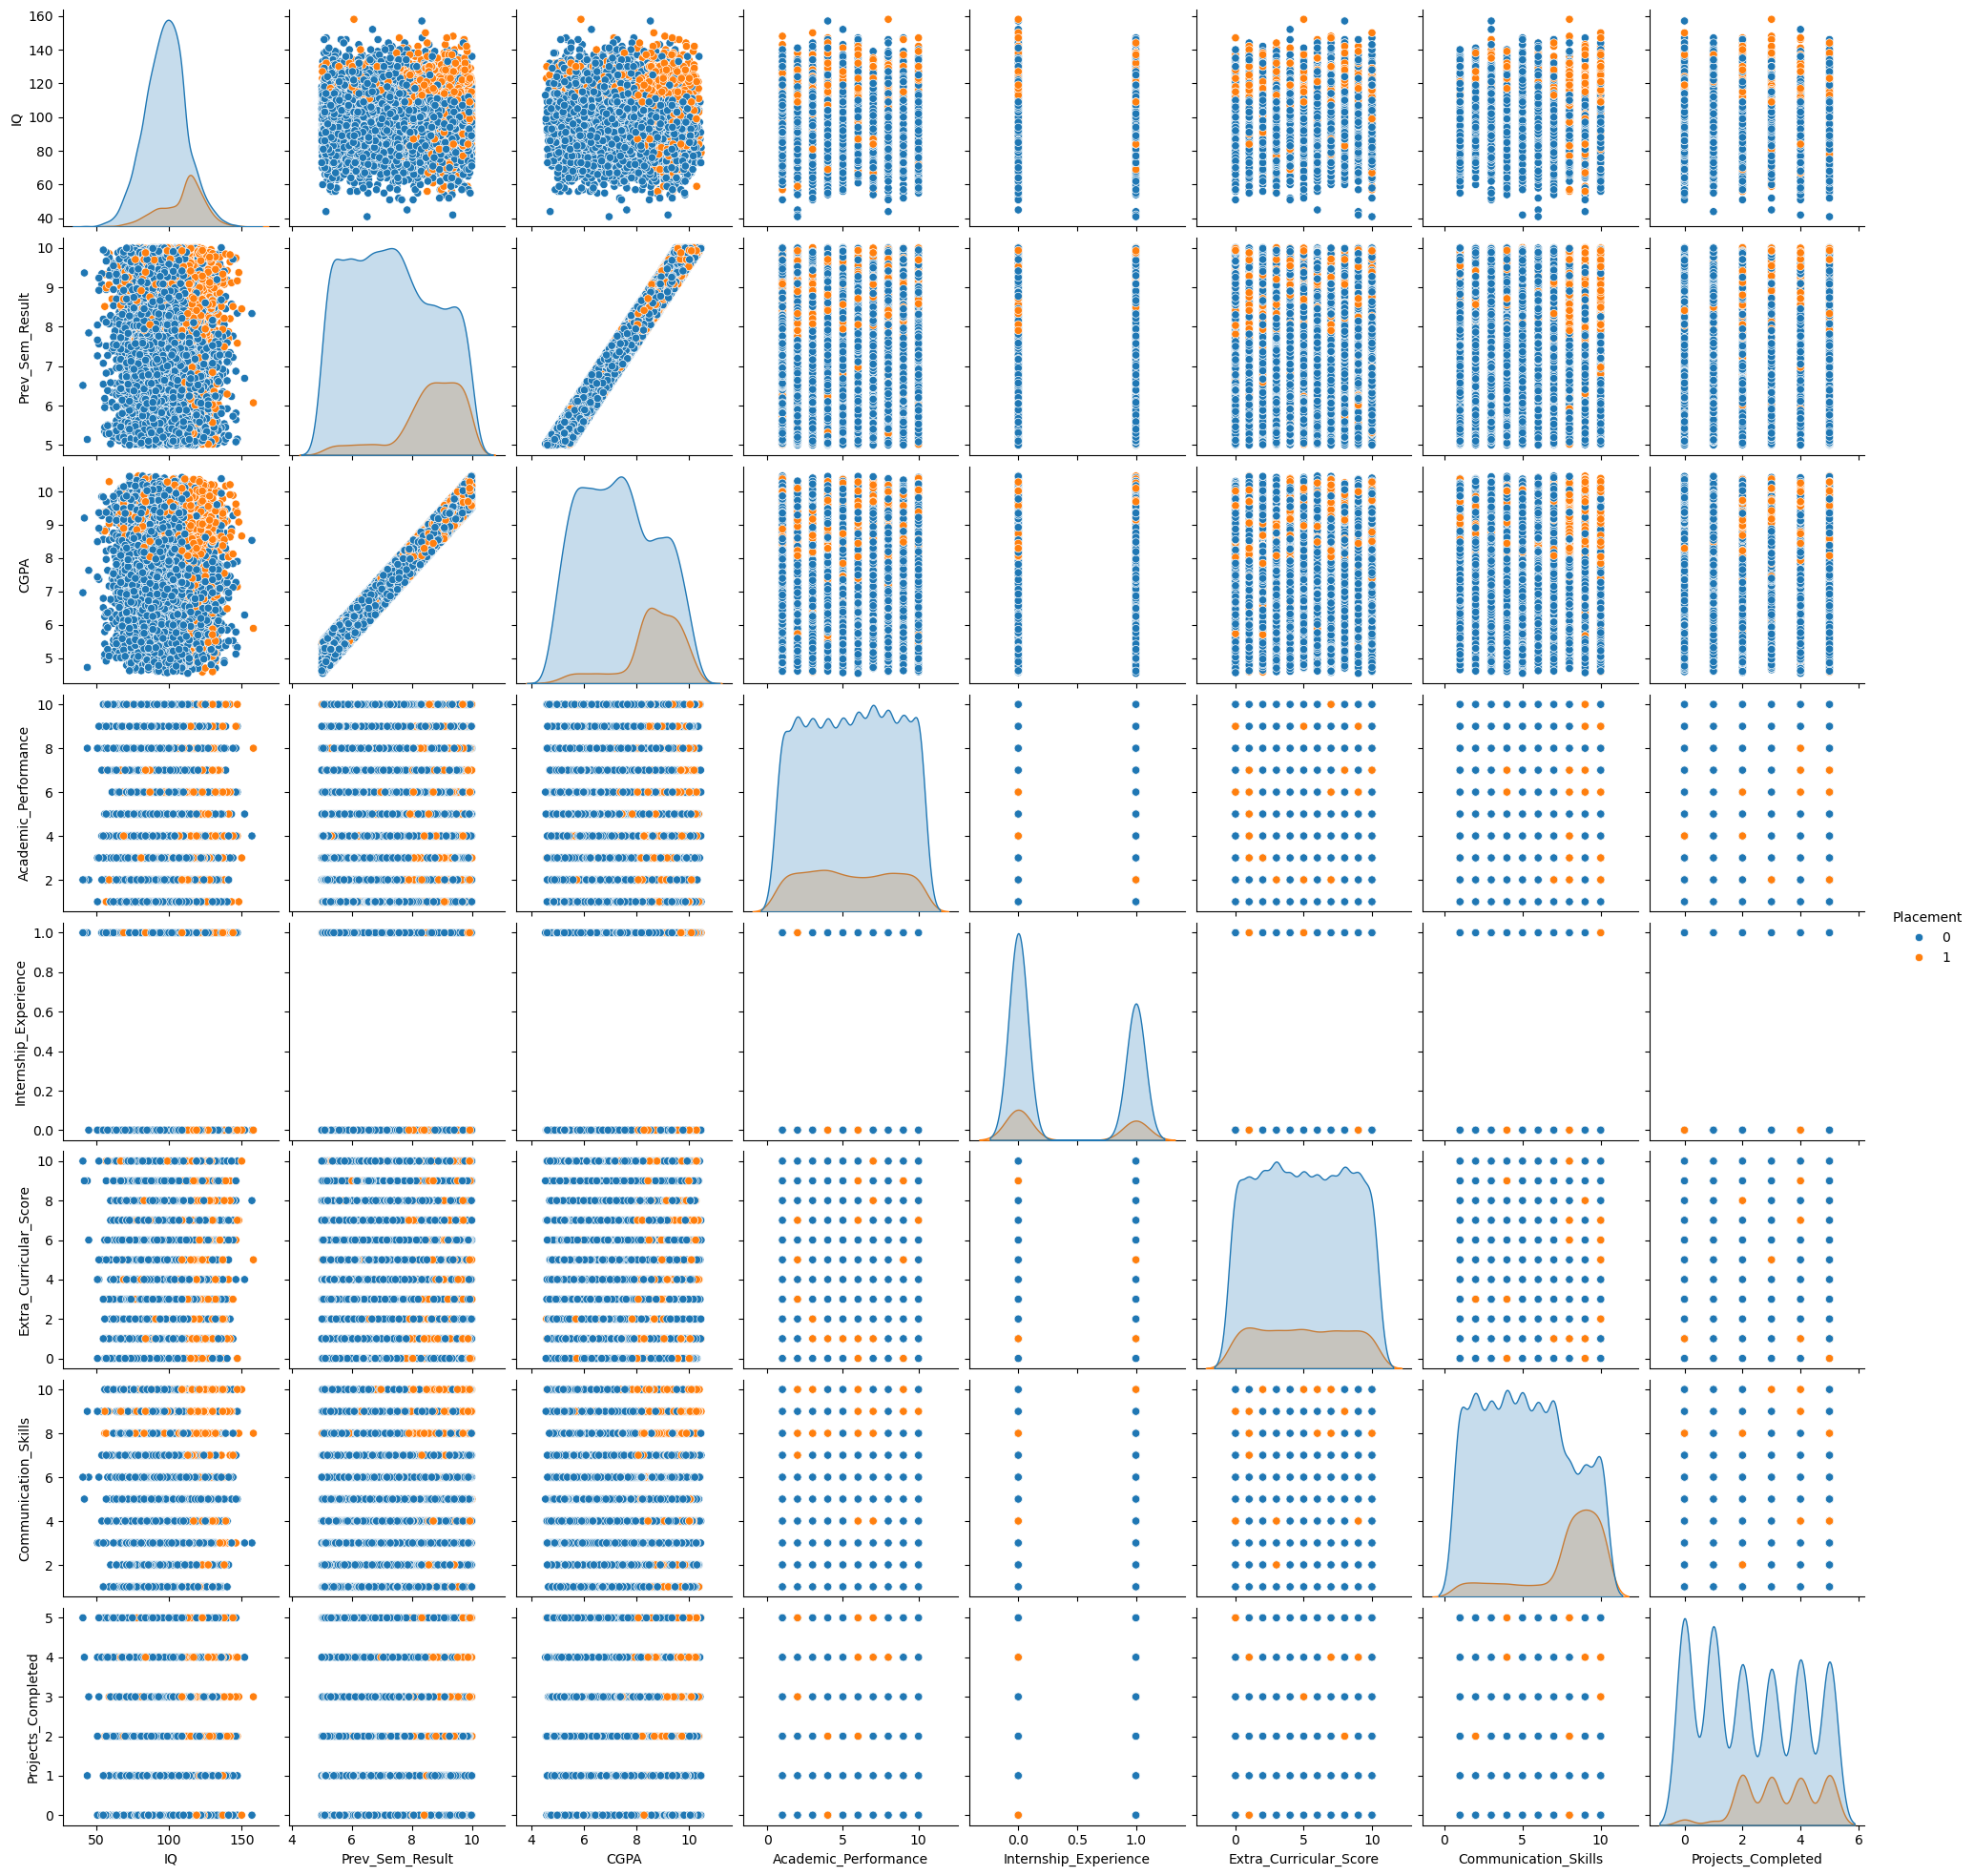

In [9]:
# Use sns.pariplot to visualize.
sns.pairplot(df, hue = "Placement")
plt.show()

## Feature Selection 

Choose the columns corresponding to the features _IQ_ and _internship experience_ to be your `X`. Target _placement_ as your `y`.

In [10]:
# Set X to the desired features.
X = df[['IQ', 'Internship_Experience']]

# Set y to be our target variable.
y = df['Placement']

## Split to Testing and Training Datasets 

In [11]:
# Split our data into testing and training pairs.
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=RANDOM_STATE)

# Print the length and width of our testing data.
print("X_train: %d rows, %d columns" % X_train.shape)
print("X_test: %d rows, %d columns" % X_test.shape)
print("y_train: %d rows, 1 column" % y_train.shape)
print("y_test: %d rows, 1 column" % y_test.shape)

X_train: 8000 rows, 2 columns
X_test: 2000 rows, 2 columns
y_train: 8000 rows, 1 column
y_test: 2000 rows, 1 column


## Build and train your model

Initialize an empty Logistic Regression model, and then fit your model to your training data. 

In [12]:
# Initalize our logistic regressionmodel.
model = LogisticRegression()
model.fit(X_train, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,None
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


## Evaluation

Make predictions with your test data and save the predictions as `y_pred`.

In [13]:
# 1. Make predictions of your test data and save them as `y_pred`.
y_pred = model.predict(X_test)
y_pred

array([0, 0, 0, ..., 0, 0, 0])

Calculate and print the accuracy, precision, recall, and F1 scores of your model.

In [14]:
# 2. Calculate and print the accuracy, precision, recall, and F1 scores of your model.

print("Accuracy Score: %f" % accuracy_score(y_test, y_pred))
print("Precision Score: %f" % precision_score(y_test, y_pred))
print("Recall Score: %f" % recall_score(y_test, y_pred))
print('F1 Score: %f' % f1_score(y_test, y_pred))

Accuracy Score: 0.829000
Precision Score: 0.333333
Recall Score: 0.030120
F1 Score: 0.055249


Plot a confusion matrix of your predicted results.

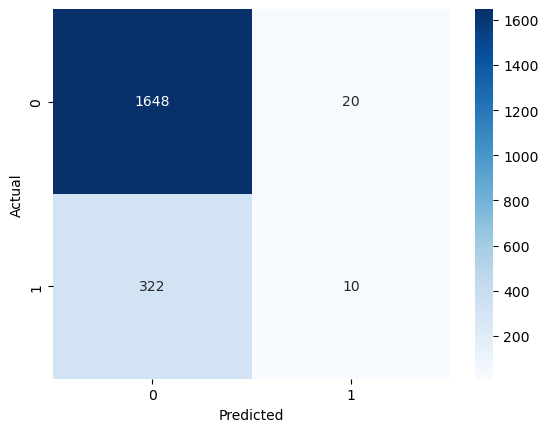

In [20]:
# 3. Plot a confusion matrix of your predicted results.
sns.heatmap(confusion_matrix(y_test, y_pred), annot = True, fmt = 'd', cmap = "Blues")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.show()


How many true positives and true negatives did your model get?

In [21]:
# How many true positives and true negatives did your model get?

true_negatives, false_positives, false_negatives, true_positives = confusion_matrix(y_test, y_pred).ravel()
print('True Negatives: %d' % true_negatives)
print('True Positives: %d' % true_positives)

True Negatives: 1648
True Positives: 10


Such awful 😞

# What is the Most Important Feature
 
Use `statsmodel` to create a summary report. Interpret the results.

In [23]:
# Add a constant term to the independent variables.
X_train_sm = sm.add_constant(X_train)

# Fit the model.
sm_model = sm.Logit(y_train, X_train_sm).fit()

# Print the summary and interpret the results.
print(sm_model.summary())

Optimization terminated successfully.
         Current function value: 0.407045
         Iterations 7
                           Logit Regression Results                           
Dep. Variable:              Placement   No. Observations:                 8000
Model:                          Logit   Df Residuals:                     7997
Method:                           MLE   Df Model:                            2
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                 0.09402
Time:                        12:58:54   Log-Likelihood:                -3256.4
converged:                       True   LL-Null:                       -3594.3
Covariance Type:            nonrobust   LLR p-value:                1.750e-147
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                    -7.3832      0.250    -29.481      0.000      -7.874      -6.

# Extra Credit: Use your brain and make a better model (as in better scores).



In [28]:
X_check = sm.add_constant(df[['CGPA', 'Communication_Skills', 'Internship_Experience', 'IQ']])
sm_check = sm.Logit(df['Placement'], X_check).fit()
print(sm_check.summary())

Optimization terminated successfully.
         Current function value: 0.259735
         Iterations 8
                           Logit Regression Results                           
Dep. Variable:              Placement   No. Observations:                10000
Model:                          Logit   Df Residuals:                     9995
Method:                           MLE   Df Model:                            4
Date:                Sat, 31 Oct 2026   Pseudo R-squ.:                  0.4219
Time:                        13:10:35   Log-Likelihood:                -2597.3
converged:                       True   LL-Null:                       -4493.3
Covariance Type:            nonrobust   LLR p-value:                     0.000
                            coef    std err          z      P>|z|      [0.025      0.975]
-----------------------------------------------------------------------------------------
const                   -23.3259      0.564    -41.326      0.000     -24.432     -22.

In [31]:
print("Unique Colleges:", df['College_ID'].nunique())
# Check placement rate across colleges
print(df.groupby('College_ID')['Placement'].mean())

Unique Colleges: 100
College_ID
CLG0001    0.100917
CLG0002    0.139535
CLG0003    0.175258
CLG0004    0.142857
CLG0005    0.151786
             ...   
CLG0096    0.232323
CLG0097    0.168317
CLG0098    0.152381
CLG0099    0.157303
CLG0100    0.175258
Name: Placement, Length: 100, dtype: float64


Accuracy Score: 0.889500
Precision Score: 0.742358
Recall Score: 0.512048
F1 Score: 0.606061


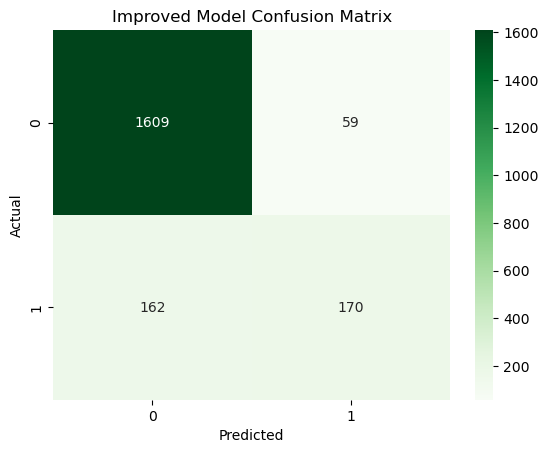

In [38]:
# Define the new X variable, and reuse the same y variable from before.
X_better = df[['CGPA', 'Communication_Skills', 'IQ']]
y_better = df['Placement']

# Split our data into testing and training. Remember to use the same random state as you used before
X_train_b, X_test_b, y_train_b, y_test_b = train_test_split(X_better, y_better, test_size=0.2, random_state=RANDOM_STATE)

# Initalize our model.
better_model = LogisticRegression(max_iter=10000, random_state=RANDOM_STATE)

# Fit-train our model using our training data.
better_model.fit(X_train_b, y_train_b)

# Make new predicitions using our testing data.
y_pred_b = better_model.predict(X_test_b)

# Print each of our scores to inspect performance.
print("Accuracy Score: %f" % accuracy_score(y_test_b, y_pred_b))
print("Precision Score: %f" % precision_score(y_test_b, y_pred_b))
print("Recall Score: %f" % recall_score(y_test_b, y_pred_b))
print('F1 Score: %f' % f1_score(y_test_b, y_pred_b))

# Plot the confusion matrix.
sns.heatmap(confusion_matrix(y_test_b, y_pred_b), annot=True, fmt="d", cmap = "Greens")
plt.title("Improved Model Confusion Matrix")
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()